# Preprocessing

In [2]:
# Recupero id autori è la versione precedente della name disambiguation, ora sto usando un algoritmo più sofisticato presente in new_name_disambiguation
import json
import re
import os
import statistiche
import math

import matplotlib.pyplot as plt
import networkx as nx
from collections import defaultdict

## Disambiguazione dei nomi

In [3]:
directory = 'openalex_macroareas_json'

In [4]:
# Normalizzazione per ogni macroarea-> commentato perché vecchia versione di name disambiguation
'''
json_file_names = [filename for filename in os.listdir(directory) if filename.endswith('.json')]

tot_autori = []

for json_file_name in json_file_names:
    
     try:
         with open(os.path.join(directory, json_file_name), 'r') as json_file:
             json_text = json.load(json_file)
             normalized_authors, name_map = recupero_id_autori.normalize_authors(json_text)
             tot_autori.append(normalized_authors)
    
     except json.JSONDecodeError as e_json:
         print(f'Errore di encoding Json al file {json_file_name}: {e_json}')
    
     except Exception as e: 
         print(f'Errore generico in {json_file_name}: {e}')
         '''

"\njson_file_names = [filename for filename in os.listdir(directory) if filename.endswith('.json')]\n\ntot_autori = []\n\nfor json_file_name in json_file_names:\n\n     try:\n         with open(os.path.join(directory, json_file_name), 'r') as json_file:\n             json_text = json.load(json_file)\n             normalized_authors, name_map = recupero_id_autori.normalize_authors(json_text)\n             tot_autori.append(normalized_authors)\n\n     except json.JSONDecodeError as e_json:\n         print(f'Errore di encoding Json al file {json_file_name}: {e_json}')\n\n     except Exception as e: \n         print(f'Errore generico in {json_file_name}: {e}')\n         "

In [5]:
# Salvataggio degli autori normalizzati
#with open('normalized_authors.json', 'w') as fout:
#        json.dump(tot_autori, fout)

In [6]:
#with open('normalized_authors.json', 'r') as file:
#     normalized_authors = json.load(file)

### Disambiguazione ulteriore poiché sono sempre presenti autori con varianti dello stesso nome
Controlliamo la somiglianza tra il cognome (che deve essere identico), le iniziali e le affiliazioni

In [7]:
#merged_authors = preprocessing.remove_duplicate_authors(normalized_authors, affiliation_threshold=0.50, name_threshold=0.90)

In [8]:
# with open('merged_authors.json', 'w') as outfile:
#        json.dump(merged_authors, outfile)

In [10]:
with open('new_merged_authors.json', 'r') as f:
        merged_authors = json.load(f)

## Estrazione statistiche

In [11]:
from statistiche import *

Numero totale di paper estratti per macroarea

In [12]:
# ci sono duplicati
papers = 0


json_file_names = [filename for filename in os.listdir(directory) if filename.endswith('.json')]

for json_file_name in json_file_names:
    
    try:
        with open(os.path.join(directory, json_file_name), 'r') as json_file:
            json_text = json.load(json_file)
            papers += len(json_text)
            print('Il settore ', json_file_name, 'contiene ', len(json_text))
    
    except json.JSONDecodeError as e_json:
        print(f'Errore di encoding Json al file {json_file_name}: {e_json}')
    
    except Exception as e: 
        print(f'Errore generico in {json_file_name}: {e}')

print('In totale sono stati estratti: ', papers, ' articoli')

Il settore  Psychology.json contiene  10733
Il settore  Philosophy.json contiene  5604
Il settore  Medicine.json contiene  26179
Il settore  Sociology.json contiene  5892
Il settore  Business.json contiene  6975
Il settore  Chemistry.json contiene  20932
Il settore  Political_science.json contiene  7489
Il settore  Geography.json contiene  7183
Il settore  Materials_science.json contiene  7599
Il settore  History.json contiene  1086
Il settore  Economics.json contiene  9316
Il settore  Engineering.json contiene  16350
Il settore  Biology.json contiene  12230
Il settore  Physics.json contiene  23240
Il settore  Art.json contiene  1049
Il settore  Environmental_science.json contiene  7917
Il settore  Mathematics.json contiene  13363
Il settore  Geology.json contiene  6421
Il settore  Computer_science.json contiene  12251
In totale sono stati estratti:  201809  articoli


Numero totale di autori estratti post disambiguazione

In [13]:
# Numero totale di autori
print(f'Il numero totale di autori trovati fin\'ora post disambiguazione è {len(merged_authors)}')

Il numero totale di autori trovati fin'ora post disambiguazione è 91145


Numero medio di collaboratori e di paper per autore

In [14]:
# Numero medio di collaboratori per paper nel dataset
avg_collaborators, std_dev_collabs, median_collabs, avg_papers = statistiche.avg_num_collaborators(merged_authors)

print(f'Il numero medio di collaboratori per ogni autore è {avg_collaborators:.2f}')
print(f'La standard deviation del numero medio di collaboratori è di {std_dev_collabs:.2f}')
print(f'La mediana del numero di collaboratori è di {median_collabs:.2f}')
print(f'Il numero medio di paper per ogni autore è {avg_papers:.2f}')

Il numero medio di collaboratori per ogni autore è 7.72
La standard deviation del numero medio di collaboratori è di 9.37
La mediana del numero di collaboratori è di 5.17
Il numero medio di paper per ogni autore è 3.42


Numero medio di affiliazioni per autore

In [15]:
# Numero medio di affiliazioni per autore
print(f'Il numero medio di istituzioni per autore è di {statistiche.avg_num_affiliations(merged_authors):.2f}')

Il numero medio di istituzioni per autore è di 1.64


Numero medio di autori per paper

In [16]:
paper_details = statistiche.print_paper_statistics(merged_authors)

Numero totale di paper unici: 88141
Numero medio di autori per paper: 3.85
Deviazione standard del numero medio di autori per paper: 4.2391051079823
Mediana del numero di autori per paper: 3
Numero minimo di autori: 1
Numero massimo di autori: 99



Distribuzione numero autori per paper:
  1 autori: 12038 paper (20.0%)
  2 autori: 10192 paper (16.9%)
  3 autori: 8743 paper (14.5%)
  4 autori: 6735 paper (11.2%)
  5 autori: 4957 paper (8.2%)
  6 autori: 3883 paper (6.5%)
  7 autori: 2910 paper (4.8%)
  8 autori: 2254 paper (3.7%)
  9 autori: 1660 paper (2.8%)
  10 autori: 1351 paper (2.2%)
  11 autori: 1067 paper (1.8%)
  12 autori: 808 paper (1.3%)
  13 autori: 608 paper (1.0%)
  14 autori: 476 paper (0.8%)
  15 autori: 367 paper (0.6%)
  16 autori: 298 paper (0.5%)
  17 autori: 251 paper (0.4%)
  18 autori: 194 paper (0.3%)
  19 autori: 175 paper (0.3%)
  20 autori: 178 paper (0.3%)
  21 autori: 128 paper (0.2%)
  22 autori: 94 paper (0.2%)
  23 autori: 76 paper (0.1%)
  24 autori: 89 paper (0.1%)
  25 autori: 47 paper (0.1%)
  26 autori: 32 paper (0.1%)
  27 autori: 51 paper (0.1%)
  28 autori: 39 paper (0.1%)
  29 autori: 42 paper (0.1%)
  30 autori: 43 paper (0.1%)
  31 autori: 32 paper (0.1%)
  32 autori: 33 paper (0.1%)
  33

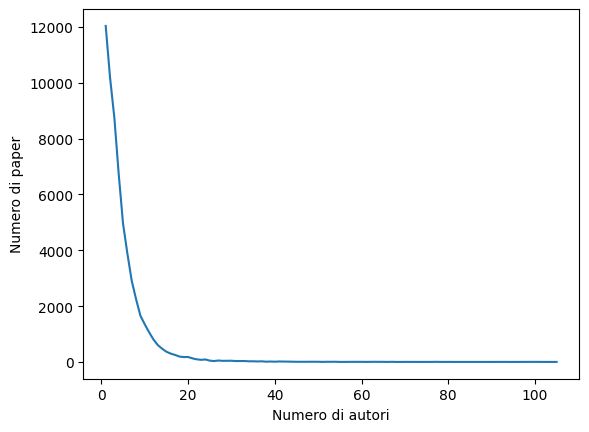

In [16]:
author_count_distribution = statistiche.analyze_authorship_patterns(merged_authors)

### Statistiche per disciplina:

Per il campo Computer science il totale degli autori estratti è di 13259
Il totale dei paper è di 7749

Per il campo Medicine il totale degli autori estratti è di 43712
Il totale dei paper è di 15383

Per il campo Psychology il totale degli autori estratti è di 7132
Il totale dei paper è di 3221

Per il campo Mathematics il totale degli autori estratti è di 1612
Il totale dei paper è di 1204

Per il campo Biology il totale degli autori estratti è di 20634
Il totale dei paper è di 6433

Per il campo Physics il totale degli autori estratti è di 8456
Il totale dei paper è di 5167

Per il campo Geology il totale degli autori estratti è di 2654
Il totale dei paper è di 1642

Per il campo Political science il totale degli autori estratti è di 471
Il totale dei paper è di 329

Per il campo Sociology il totale degli autori estratti è di 428
Il totale dei paper è di 269

Per il campo Economics il totale degli autori estratti è di 1049
Il totale dei paper è di 869

Per il campo Materials science

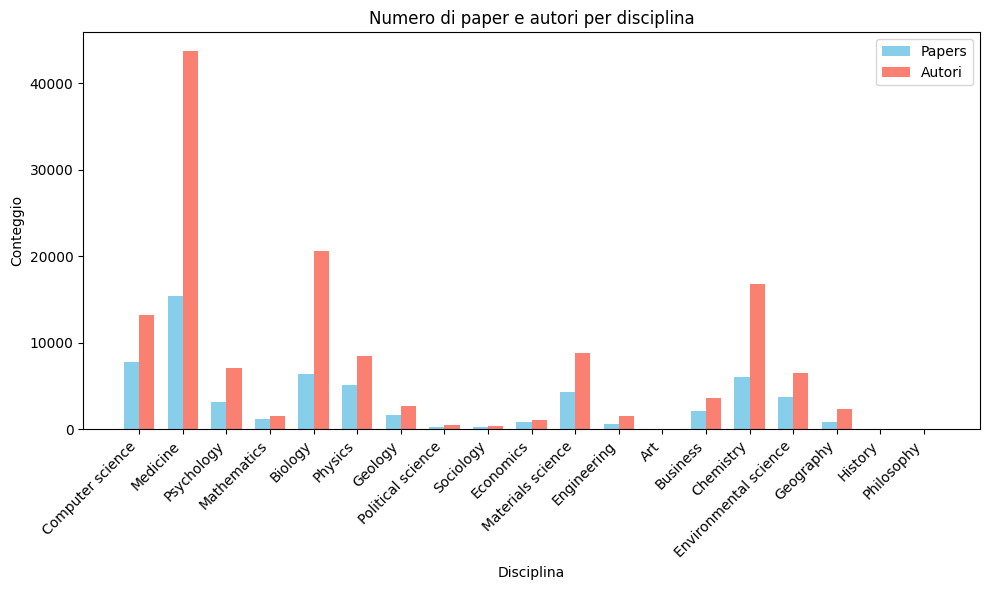

In [17]:
macroareas = statistiche.tot_authors_and_papers_by_area(merged_authors)

In [18]:
macroareas

{'Computer science': {'Authors': {'Fabio Crescimbini',
   'Chiara Franciosi',
   'Giovanna Turvani',
   'Marco Marconi',
   'Federico Riva',
   'Marco Alessandro Minetto',
   'Ines Rehbein',
   'Antonio Formisano',
   'Salvatore Mónaco',
   'Alessandro Flammini',
   'Daniele Landi',
   'Michela Spagnuolo',
   'Leon van der Wal',
   'Daniela Pedrini',
   'Anna Esposito',
   'Mario Lauria',
   'A. M. Bykov',
   'Federico Accornero',
   'Maddalena Mugnosso',
   'T. Theodorou',
   'Alessandro Oltramari',
   'David Melcher',
   'Tilmann Gneiting',
   'Livia Persano Oddo',
   'Stefania Della Penna',
   'Giovanna Trianni',
   'Giovanni Chiarion',
   'Sergey Tulyakov',
   'Marco Ratto',
   'F Doni',
   'Michele Missikoff',
   'Susy Piovesana',
   'Giuseppe Riva',
   'Xiaojun Wan',
   'Michel D. Ferrari',
   'Luca Turella',
   'Luigi Palopoli',
   'Alessandro Finamore',
   'Diego Reforgiato Recupero',
   'Donato Romano',
   'I. Manno',
   'Giovanni Cuda',
   'Fabrizio Trotta',
   'Emiliano Cris

Il numero medio di paper per autore nell'ambito Computer science è 1.7861075495889585 con deviazione standard uguale a 1.9872776023232257
Il numero medio di paper per autore nell'ambito Medicine è 2.2953651171303076 con deviazione standard uguale a 3.080000089772706
Il numero medio di paper per autore nell'ambito Psychology è 1.903954010095345 con deviazione standard uguale a 2.121228086423519
Il numero medio di paper per autore nell'ambito Mathematics è 1.66439205955335 con deviazione standard uguale a 1.8203147997966684
Il numero medio di paper per autore nell'ambito Biology è 1.7252108170979936 con deviazione standard uguale a 1.6031002684564961
Il numero medio di paper per autore nell'ambito Physics è 4.438505203405866 con deviazione standard uguale a 9.38394494559358
Il numero medio di paper per autore nell'ambito Geology è 2.166164280331575 con deviazione standard uguale a 2.4530037530237947
Il numero medio di paper per autore nell'ambito Political science è 1.2505307855626326 co

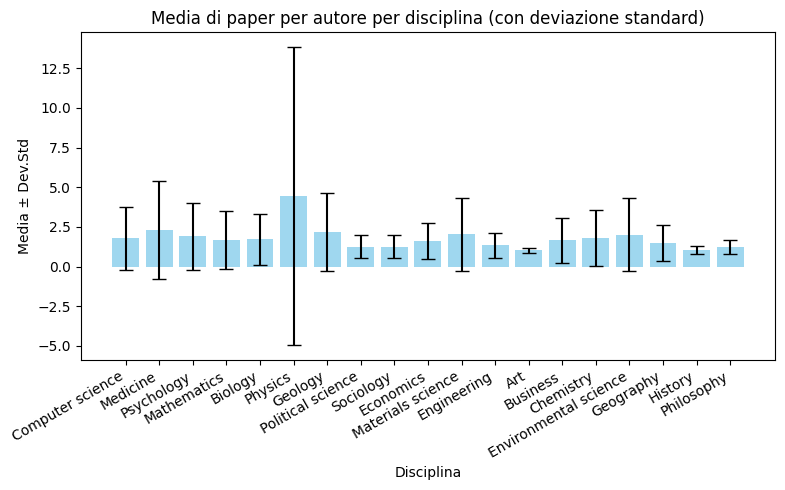

In [19]:
results = statistiche.avg_papers_by_area(merged_authors)

Disciplina: Computer science
  Media dei collaboratori per paper: 3.69
  Varianza: 37.41, Dev.Std: 6.12
  Totale paper: 15565, Range: 0–99

Disciplina: Medicine
  Media dei collaboratori per paper: 9.69
  Varianza: 112.01, Dev.Std: 10.58
  Totale paper: 43375, Range: 0–99

Disciplina: Psychology
  Media dei collaboratori per paper: 4.95
  Varianza: 27.36, Dev.Std: 5.23
  Totale paper: 6464, Range: 0–91

Disciplina: Mathematics
  Media dei collaboratori per paper: 1.83
  Varianza: 5.93, Dev.Std: 2.44
  Totale paper: 1859, Range: 0–22

Disciplina: Biology
  Media dei collaboratori per paper: 7.20
  Varianza: 34.08, Dev.Std: 5.84
  Totale paper: 18051, Range: 0–93

Disciplina: Physics
  Media dei collaboratori per paper: 17.79
  Varianza: 352.74, Dev.Std: 18.78
  Totale paper: 17307, Range: 0–98

Disciplina: Geology
  Media dei collaboratori per paper: 6.10
  Varianza: 94.42, Dev.Std: 9.72
  Totale paper: 4059, Range: 0–72

Disciplina: Political science
  Media dei collaboratori per paper

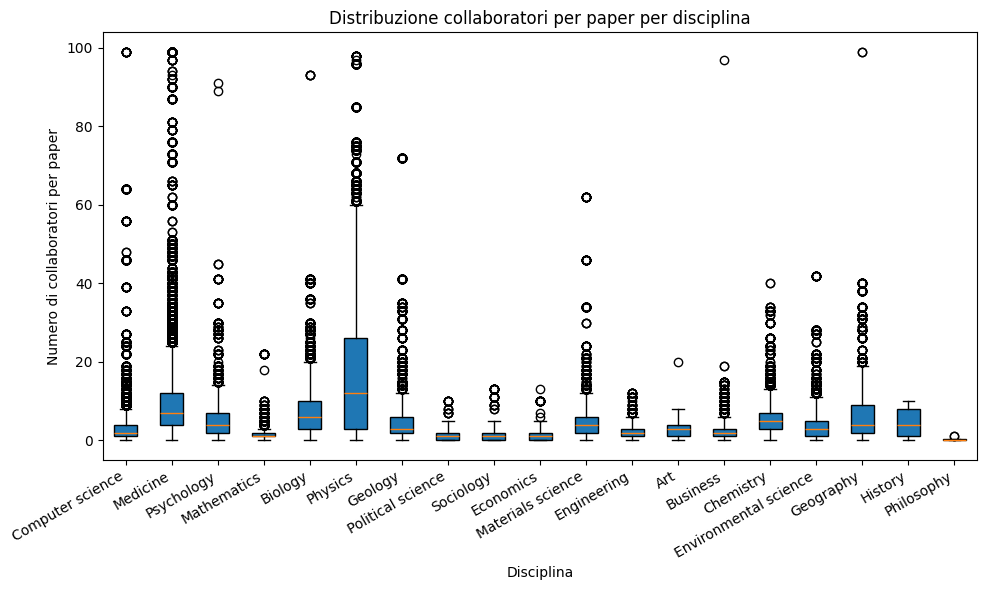

In [20]:
results_collabs_by_area = statistiche.avg_collaborators_by_area(merged_authors)

Si nota il trend già evidenziato in punti precedenti come nel calcolo del numero di autori per paper: per la maggior parte delle discipline la distribuzione presenta un nucleo piuttosto compatto di fenomeni distributi attorno alla mediana, ma con un foltissimo numero di outliers nella parte alta della distribuzione ovviamente. Per alcune discipline questo fenomeno si realizza maggiormente, come per Medicina e Fisica, ma bisogna ricordare che queste sono anche le aree maggiormente rappresentate.

### Statistiche sulle istituzioni

In [21]:
def number_of_institutions(data):

    istituzioni = set()

    for author, infos in data.items():

        anni = infos.get('anno', {})

        for anno, affiliazioni in anni.items():
            
            if isinstance(affiliazioni, list):
                for i in affiliazioni:
                    istituzioni.add(i)

    print(f'Il totale di affiliazioni presenti è di {len(istituzioni)}')

    return list(istituzioni)


In [22]:
istituzioni = number_of_institutions(merged_authors)

Il totale di affiliazioni presenti è di 1103


In [23]:
#with open('istituzioni.json', 'w') as outfile:
#       json.dump(istituzioni, outfile)

with open('Data/located_institutions_2.json', 'r') as infile:
       istituzioni = json.load(infile)

In [24]:
istituzioni_non_localizzate = []
for istituzione, dati in istituzioni.items():
    if dati == [None, None]:
        istituzioni_non_localizzate.append(istituzione)

print(f'Non sono state localizzate {len(istituzioni_non_localizzate)} istituzioni, il {len(istituzioni_non_localizzate)/len(istituzioni)*100:.2f}%. Queste sono:')
for x in istituzioni_non_localizzate:
    print(f" - {x}")

Non sono state localizzate 313 istituzioni, il 28.38%. Queste sono:
 - Center for Sustainable Future Technologies
 - Fondazione Umberto Di Mario
 - Don Carlo Gnocchi Foundation
 - Radiolabs
 - Iris Vernici (Italy)
 - Associazione Medici Diabetologi
 - The Abdus Salam International Centre for Theoretical Physics (ICTP)
 - European Centre for Training and Research in Earthquake Engineering
 - Mario Negri Institute for Pharmacological Research
 - Fondazione Gimema Onlus
 - Procter & Gamble (Italy)
 - Cystic Fibrosis Research Foundation
 - Istituto Mediterraneo per i Trapianti e Terapie ad Alta Specializzazione
 - Azienda Ospedaliero Universitaria Ospedali Riuniti
 - Pirelli (Italy)
 - International Centre for Genetic Engineering and Biotechnology
 - ANT Foundation Italy Onlus
 - Italian Association for Cancer Research
 - Superconducting and other Innovative Materials and Devices Institute
 - Quanta System (Italy)
 - Azienda Ospedaliera Fatebenefratelli e Oftalmico
 - Center For Reconstruc

### Anni coperti dai dati

In [25]:
def anni_coperti(data):
    anni_coperti= set()

    for author, infos in data.items():

        anni = infos.get('anno', {})

        for anno, affiliazioni in anni.items():
            anni_coperti.add(anno)
    return anni_coperti

In [26]:
anni_coperti = anni_coperti(merged_authors)

In [27]:
anni_coperti

{'2000',
 '2001',
 '2002',
 '2003',
 '2004',
 '2005',
 '2006',
 '2007',
 '2008',
 '2009',
 '2010',
 '2011',
 '2012',
 '2013',
 '2014',
 '2015',
 '2016',
 '2017',
 '2018',
 '2019',
 '2020',
 '2021',
 '2022',
 '2023',
 '2024',
 '2025'}

Percentuale di autori che hanno tot anni coperti

In [28]:
def copertura_autori(dizionario):

    for i in range(0, 26):

        autori = 0

        for autore, infos in dizionario.items():

            anni = infos.get('anno', {})

            if len(anni) == i:
                autori +=1

        print(f'La percentuale di autori con copertura attuale uguale a {i} è di {(autori/len(merged_authors))*100:.2f}%')    


In [29]:
copertura_autori(merged_authors)

La percentuale di autori con copertura attuale uguale a 0 è di 0.00%
La percentuale di autori con copertura attuale uguale a 1 è di 8.40%
La percentuale di autori con copertura attuale uguale a 2 è di 58.06%
La percentuale di autori con copertura attuale uguale a 3 è di 18.62%
La percentuale di autori con copertura attuale uguale a 4 è di 7.46%
La percentuale di autori con copertura attuale uguale a 5 è di 3.48%
La percentuale di autori con copertura attuale uguale a 6 è di 1.69%
La percentuale di autori con copertura attuale uguale a 7 è di 1.00%
La percentuale di autori con copertura attuale uguale a 8 è di 0.49%
La percentuale di autori con copertura attuale uguale a 9 è di 0.31%
La percentuale di autori con copertura attuale uguale a 10 è di 0.20%
La percentuale di autori con copertura attuale uguale a 11 è di 0.12%
La percentuale di autori con copertura attuale uguale a 12 è di 0.08%
La percentuale di autori con copertura attuale uguale a 13 è di 0.04%
La percentuale di autori con

### Analisi delle istituzioni associate ad ogni autore e costruzione grafo bipartito

In [30]:
merged_authors

{'Alessandro Liberati': {'collaborators_by_paper': {'Going from evidence to recommendations': [[],
    'Computer science'],
   'GRADE guidelines: 10. Considering resource use and rating the quality of economic evidence': [['Silvia Pregno',
     'Massimo Brunetti'],
    'Computer science'],
   'Reprint—Preferred Reporting Items for Systematic Reviews and Meta-Analyses: The PRISMA Statement': [[],
    'Medicine'],
   'Incorporating considerations of resources use into grading recommendations': [['Holger J. Schünemann'],
    'Computer science'],
   'What contributions do languages other than English make on the results of meta-analyses?': [[],
    'Medicine'],
   'Preferred reporting items for systematic review and meta-analysis protocols (PRISMA-P) 2015: elaboration and explanation': [[],
    'Computer science'],
   'Preferred reporting items for systematic reviews and meta-analyses: the PRISMA statement': [[],
    'Computer science']},
  'anno': {'2000': ['Mario Negri Institute for Phar

In [31]:
def sorted_affiliations(data):

    for author, information in data.items():
        anni_affiliazioni = information.get("anno", {})
        
        sorted_anni = dict(sorted(anni_affiliazioni.items(), key=lambda x: int(x[0])))
        
        information["anno"] = sorted_anni

    return data

merged_authors = sorted_affiliations(merged_authors)